In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


def wape(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return np.abs(y_true - y_pred).sum() / y_true.sum()





In [2]:
df_future = pd.read_csv('future_plan_4w.csv')
df_inven = pd.read_csv('inventory_now.csv')
df_product = pd.read_csv('product_master.csv')
df_review = pd.read_csv('reviews.csv')
df_sales_week = pd.read_csv('sales_weekly.csv')
df_submission = pd.read_csv('submission_template.csv')
df_ad_spend_daily = pd.read_csv('ad_spend_daily.csv')
df_promotion = pd.read_csv('promotions.csv')
df_sales_daily = pd.read_csv('sales_daily.csv')
df_answer_key = pd.read_csv('answer_key.csv')



In [3]:
## 그림그려주는 함수 만들기
def QuantilePlot(df,colum_name,taget_name,count_or_mean,nonzero=False) :
    df_temp = df.copy()
    if nonzero==False :
        df_temp[colum_name+'_group'] = pd.cut(
        df_temp[colum_name],
        bins=[-1, 0,df_temp[colum_name].quantile(0.1),df_temp[colum_name].quantile(0.2),df_temp[colum_name].quantile(0.3),
             df_temp[colum_name].quantile(0.4),df_temp[colum_name].quantile(0.5),df_temp[colum_name].quantile(0.6),
             df_temp[colum_name].quantile(0.7),df_temp[colum_name].quantile(0.8),df_temp[colum_name].quantile(0.9), np.inf],
        labels=['0', 'q1','q2','q3','q4','q5', 'q6', 'q7','q8', 'q9', '~max'] 
        )
    else :
        df_nonzero = df_temp[df_temp[colum_name]!=0]
        df_temp[colum_name+'_group'] = pd.cut(
        df_nonzero[colum_name],
        bins=[-1, 0,df_nonzero[colum_name].quantile(0.1),df_nonzero[colum_name].quantile(0.2),df_nonzero[colum_name].quantile(0.3),
             df_nonzero[colum_name].quantile(0.4),df_nonzero[colum_name].quantile(0.5),df_nonzero[colum_name].quantile(0.6),
             df_nonzero[colum_name].quantile(0.7),df_nonzero[colum_name].quantile(0.8),df_nonzero[colum_name].quantile(0.9), np.inf],
        labels=['0', 'q1','q2','q3','q4','q5', 'q6', 'q7','q8', 'q9', '~max'] 
        )
    
    

        
    purchase = df_temp.groupby(colum_name+'_group', observed=False)[taget_name].agg(
        ['count', 'mean']
    )
    sns.barplot(purchase[count_or_mean])
    plt.show()
    return None



In [4]:
display(df_answer_key.head())
print()
display(df_answer_key.info())
print()
display(df_answer_key.describe(include='all'))
print()
display(df_answer_key.shape)


,sku,channel,week_start,actual_units,stockout_days,scored,baseline_4wk_avg
0,A-SRM-100,own_mall,2026-07-27,157,0,1,166.50
1,A-SRM-100,own_mall,2026-08-03,109,0,1,166.50
2,A-SRM-100,own_mall,2026-08-10,197,0,1,166.50
3,A-SRM-100,own_mall,2026-08-17,137,0,1,166.50
4,A-SRM-100,coupang,2026-07-27,171,0,1,211.25



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   sku               80 non-null     object 
 1   channel           80 non-null     object 
 2   week_start        80 non-null     object 
 3   actual_units      80 non-null     int64  
 4   stockout_days     80 non-null     int64  
 5   scored            80 non-null     int64  
 6   baseline_4wk_avg  80 non-null     float64
dtypes: float64(1), int64(3), object(3)
memory usage: 4.5+ KB


None

,sku,channel,week_start,actual_units,stockout_days,scored,baseline_4wk_avg
count,80,80,80,80.000000,80.00000,80.00000,80.000000
unique,5,4,4,NaN,NaN,NaN,NaN
top,A-SRM-100,own_mall,2026-07-27,NaN,NaN,NaN,NaN
freq,16,20,20,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,71.712500,0.17500,0.97500,68.825000
std,NaN,NaN,NaN,45.779381,1.09977,0.15711,45.140154
min,NaN,NaN,NaN,0.000000,0.00000,0.00000,24.250000
25%,NaN,NaN,NaN,42.000000,0.00000,1.00000,39.500000
50%,NaN,NaN,NaN,57.000000,0.00000,1.00000,56.000000
75%,NaN,NaN,NaN,82.250000,0.00000,1.00000,78.937500


(80, 7)

In [5]:
display(df_future.head())
print()
display(df_future.info())
print()
display(df_future.describe(include='all'))
print()
display(df_future.shape)




,sku,product_name,channel,week_start,currency,planned_ad_spend,promo_days,promo_discount
0,A-SRM-100,발효 퍼스트 앰플 100ml,amazon_us,2026-07-27,USD,1947.0,0,0.0
1,A-CRM-050,장벽 크림 50ml,amazon_us,2026-07-27,USD,1947.0,0,0.0
2,A-CAP-HY,수분 캡슐 앰플 40caps,amazon_us,2026-07-27,USD,1947.0,0,0.0
3,A-CAP-VC,광채 캡슐 앰플 40caps,amazon_us,2026-07-27,USD,1947.0,0,0.0
4,A-CAP-PN,진정 캡슐 앰플 40caps,amazon_us,2026-07-27,USD,1947.0,0,0.0



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   sku               80 non-null     object 
 1   product_name      80 non-null     object 
 2   channel           80 non-null     object 
 3   week_start        80 non-null     object 
 4   currency          80 non-null     object 
 5   planned_ad_spend  80 non-null     float64
 6   promo_days        80 non-null     int64  
 7   promo_discount    80 non-null     float64
dtypes: float64(2), int64(1), object(5)
memory usage: 5.1+ KB


None

,sku,product_name,channel,week_start,currency,planned_ad_spend,promo_days,promo_discount
count,80,80,80,80,80,80.000000,80.000000,80.00000
unique,5,5,4,4,2,NaN,NaN,NaN
top,A-SRM-100,발효 퍼스트 앰플 100ml,amazon_us,2026-07-27,KRW,NaN,NaN,NaN
freq,16,16,20,20,60,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,447841.687500,0.625000,0.06250
std,NaN,NaN,NaN,NaN,NaN,294058.502461,1.372192,0.11321
min,NaN,NaN,NaN,NaN,NaN,1947.000000,0.000000,0.00000
25%,NaN,NaN,NaN,NaN,NaN,331063.000000,0.000000,0.00000
50%,NaN,NaN,NaN,NaN,NaN,472897.000000,0.000000,0.00000
75%,NaN,NaN,NaN,NaN,NaN,604532.250000,0.250000,0.03750


(80, 8)

In [6]:
display(df_inven.head(10))
print()
display(df_inven.info())
print()
display(df_inven.describe(include='all'))
print()
display(df_inven.shape)

,as_of,location,used_by,sku,product_name,on_hand,open_po_qty,lead_time_days,moq
0,2026-07-26,AMZ_FBA,amazon_us,A-CAP-HY,수분 캡슐 앰플 40caps,139,710,35,500
1,2026-07-26,KR_WH,"own_mall, coupang, naver",A-CAP-HY,수분 캡슐 앰플 40caps,1187,800,14,500
2,2026-07-26,AMZ_FBA,amazon_us,A-CAP-PN,진정 캡슐 앰플 40caps,0,4000,35,500
3,2026-07-26,KR_WH,"own_mall, coupang, naver",A-CAP-PN,진정 캡슐 앰플 40caps,301,800,14,500
4,2026-07-26,AMZ_FBA,amazon_us,A-CAP-VC,광채 캡슐 앰플 40caps,146,808,35,500
5,2026-07-26,KR_WH,"own_mall, coupang, naver",A-CAP-VC,광채 캡슐 앰플 40caps,766,1200,14,500
6,2026-07-26,AMZ_FBA,amazon_us,A-CRM-050,장벽 크림 50ml,145,846,35,500
7,2026-07-26,KR_WH,"own_mall, coupang, naver",A-CRM-050,장벽 크림 50ml,1736,1300,14,500
8,2026-07-26,AMZ_FBA,amazon_us,A-SRM-100,발효 퍼스트 앰플 100ml,468,2365,35,500
9,2026-07-26,KR_WH,"own_mall, coupang, naver",A-SRM-100,발효 퍼스트 앰플 100ml,3492,2500,14,500



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   as_of           10 non-null     object
 1   location        10 non-null     object
 2   used_by         10 non-null     object
 3   sku             10 non-null     object
 4   product_name    10 non-null     object
 5   on_hand         10 non-null     int64 
 6   open_po_qty     10 non-null     int64 
 7   lead_time_days  10 non-null     int64 
 8   moq             10 non-null     int64 
dtypes: int64(4), object(5)
memory usage: 848.0+ bytes


None

,as_of,location,used_by,sku,product_name,on_hand,open_po_qty,lead_time_days,moq
count,10,10,10,10,10,10.000000,10.000000,10.000000,10.0
unique,1,2,2,5,5,NaN,NaN,NaN,NaN
top,2026-07-26,AMZ_FBA,amazon_us,A-CAP-HY,수분 캡슐 앰플 40caps,NaN,NaN,NaN,NaN
freq,10,5,5,2,2,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,838.000000,1532.900000,24.500000,500.0
std,NaN,NaN,NaN,NaN,NaN,1082.811772,1086.691252,11.067972,0.0
min,NaN,NaN,NaN,NaN,NaN,0.000000,710.000000,14.000000,500.0
25%,NaN,NaN,NaN,NaN,NaN,145.250000,802.000000,14.000000,500.0
50%,NaN,NaN,NaN,NaN,NaN,384.500000,1023.000000,24.500000,500.0
75%,NaN,NaN,NaN,NaN,NaN,1081.750000,2098.750000,35.000000,500.0


(10, 9)

In [7]:
display(df_product.head())
print()
display(df_product.info())
print()
display(df_product.describe(include='all'))
print()
display(df_product.shape)

,sku,product_name,unit_cost_krw,list_price_krw,list_price_usd,lead_time_domestic_days,lead_time_fba_days,moq_units,fba_fee_usd,fba_storage_fee_usd_per_unit_month
0,A-SRM-100,발효 퍼스트 앰플 100ml,9500,38000,29.9,14,35,500,5.4,0.08
1,A-CRM-050,장벽 크림 50ml,10500,42000,39.9,14,35,500,4.9,0.05
2,A-CAP-HY,수분 캡슐 앰플 40caps,11250,45000,39.9,14,35,500,4.9,0.05
3,A-CAP-VC,광채 캡슐 앰플 40caps,11250,45000,39.9,14,35,500,4.9,0.05
4,A-CAP-PN,진정 캡슐 앰플 40caps,11250,45000,39.9,14,35,500,4.9,0.05



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 10 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   sku                                 5 non-null      object 
 1   product_name                        5 non-null      object 
 2   unit_cost_krw                       5 non-null      int64  
 3   list_price_krw                      5 non-null      int64  
 4   list_price_usd                      5 non-null      float64
 5   lead_time_domestic_days             5 non-null      int64  
 6   lead_time_fba_days                  5 non-null      int64  
 7   moq_units                           5 non-null      int64  
 8   fba_fee_usd                         5 non-null      float64
 9   fba_storage_fee_usd_per_unit_month  5 non-null      float64
dtypes: float64(3), int64(5), object(2)
memory usage: 528.0+ bytes


None

,sku,product_name,unit_cost_krw,list_price_krw,list_price_usd,lead_time_domestic_days,lead_time_fba_days,moq_units,fba_fee_usd,fba_storage_fee_usd_per_unit_month
count,5,5,5.00000,5.000000,5.000000,5.0,5.0,5.0,5.000000,5.000000
unique,5,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,A-SRM-100,발효 퍼스트 앰플 100ml,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,10750.00000,43000.000000,37.900000,14.0,35.0,500.0,5.000000,0.056000
std,NaN,NaN,770.55175,3082.207001,4.472136,0.0,0.0,0.0,0.223607,0.013416
min,NaN,NaN,9500.00000,38000.000000,29.900000,14.0,35.0,500.0,4.900000,0.050000
25%,NaN,NaN,10500.00000,42000.000000,39.900000,14.0,35.0,500.0,4.900000,0.050000
50%,NaN,NaN,11250.00000,45000.000000,39.900000,14.0,35.0,500.0,4.900000,0.050000
75%,NaN,NaN,11250.00000,45000.000000,39.900000,14.0,35.0,500.0,4.900000,0.050000


(5, 10)

In [8]:
display(df_review.head())
print()
display(df_review.info())
print()
display(df_review.describe(include='all'))
print()
display(df_review.shape)

,review_id,date,brand,is_own,product_code,product_name,channel,rating,language,text
0,R00080,2024-08-26,Brand A,True,A-CRM-050,장벽 크림 50ml,coupang,5,ko,수분감이 좋아서 재구매했어요.
1,R01915,2024-08-26,Competitor X,False,X Snail Essence 100ml,X Snail Essence 100ml,amazon_us,5,en,"Basically unscented, which I love. Keeps my sk..."
2,R02253,2024-08-26,Competitor Y,False,Y Ceramide Cream 50ml,Y Ceramide Cream 50ml,amazon_us,2,en,Broke me out after a week. Basically unscented...
3,R00305,2024-08-27,Brand A,True,A-CAP-VC,광채 캡슐 앰플 40caps,own_mall,5,ko,끈적임 없이 쏙 스며들어요. 붉은기가 진정되는 느낌이에요.
4,R00067,2024-08-28,Brand A,True,A-CAP-PN,진정 캡슐 앰플 40caps,naver,5,ko,촉촉함이 오래가요.



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2507 entries, 0 to 2506
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   review_id     2507 non-null   object
 1   date          2507 non-null   object
 2   brand         2507 non-null   object
 3   is_own        2507 non-null   bool  
 4   product_code  2507 non-null   object
 5   product_name  2507 non-null   object
 6   channel       2507 non-null   object
 7   rating        2507 non-null   int64 
 8   language      2507 non-null   object
 9   text          2507 non-null   object
dtypes: bool(1), int64(1), object(8)
memory usage: 178.8+ KB


None

,review_id,date,brand,is_own,product_code,product_name,channel,rating,language,text
count,2507,2507,2507,2507,2507,2507,2507,2507.000000,2507,2507
unique,2507,680,4,2,8,8,4,NaN,2,740
top,R00080,2026-07-02,Brand A,True,A-SRM-100,발효 퍼스트 앰플 100ml,amazon_us,NaN,ko,"Basically unscented, which I love."
freq,1,11,1501,1501,543,543,1072,NaN,1435,50
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.009573,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.154430,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.000000,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000,NaN,NaN


(2507, 10)

In [9]:
display(df_sales_week.head(20))
print()
display(df_sales_week.info())
print()
display(df_sales_week.describe(include='all'))
print()
display(df_sales_week.shape)

,week_start,sku,product_name,channel,currency,units,ad_spend,promo_days,promo_discount,stockout_days
0,2024-08-26,A-SRM-100,발효 퍼스트 앰플 100ml,own_mall,KRW,132,892418.0,0,0.00,0
1,2024-08-26,A-CRM-050,장벽 크림 50ml,own_mall,KRW,55,892418.0,0,0.00,0
2,2024-08-26,A-CAP-HY,수분 캡슐 앰플 40caps,own_mall,KRW,32,892418.0,0,0.00,0
3,2024-08-26,A-CAP-VC,광채 캡슐 앰플 40caps,own_mall,KRW,65,892418.0,0,0.00,0
4,2024-08-26,A-CAP-PN,진정 캡슐 앰플 40caps,own_mall,KRW,37,892418.0,0,0.00,0
5,2024-09-02,A-SRM-100,발효 퍼스트 앰플 100ml,own_mall,KRW,172,706875.0,0,0.00,0
6,2024-09-02,A-CRM-050,장벽 크림 50ml,own_mall,KRW,90,706875.0,0,0.00,0
7,2024-09-02,A-CAP-HY,수분 캡슐 앰플 40caps,own_mall,KRW,49,706875.0,0,0.00,0
8,2024-09-02,A-CAP-VC,광채 캡슐 앰플 40caps,own_mall,KRW,50,706875.0,0,0.00,0
9,2024-09-02,A-CAP-PN,진정 캡슐 앰플 40caps,own_mall,KRW,60,706875.0,0,0.00,0



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1530 entries, 0 to 1529
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   week_start      1530 non-null   object 
 1   sku             1530 non-null   object 
 2   product_name    1530 non-null   object 
 3   channel         1530 non-null   object 
 4   currency        1530 non-null   object 
 5   units           1530 non-null   int64  
 6   ad_spend        1530 non-null   float64
 7   promo_days      1530 non-null   int64  
 8   promo_discount  1530 non-null   float64
 9   stockout_days   1530 non-null   int64  
dtypes: float64(2), int64(3), object(5)
memory usage: 119.7+ KB


None

,week_start,sku,product_name,channel,currency,units,ad_spend,promo_days,promo_discount,stockout_days
count,1530,1530,1530,1530,1530,1530.000000,1.530000e+03,1530.000000,1530.000000,1530.000000
unique,100,5,5,4,2,NaN,NaN,NaN,NaN,NaN
top,2026-07-20,A-SRM-100,발효 퍼스트 앰플 100ml,own_mall,KRW,NaN,NaN,NaN,NaN,NaN
freq,20,306,306,500,1500,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,85.322876,7.735982e+05,1.098039,0.064248,0.070588
std,NaN,NaN,NaN,NaN,NaN,59.859594,3.784323e+05,2.079721,0.105721,0.688301
min,NaN,NaN,NaN,NaN,NaN,0.000000,1.153370e+03,0.000000,0.000000,0.000000
25%,NaN,NaN,NaN,NaN,NaN,46.000000,4.773050e+05,0.000000,0.000000,0.000000
50%,NaN,NaN,NaN,NaN,NaN,65.000000,6.820520e+05,0.000000,0.000000,0.000000
75%,NaN,NaN,NaN,NaN,NaN,109.000000,9.355540e+05,1.000000,0.150000,0.000000


(1530, 10)

In [10]:
display(df_submission.head())
print()
display(df_submission.info())
print()
display(df_submission.describe(include='all'))
print()

,sku,channel,week_start,pred_units
0,A-SRM-100,amazon_us,2026-07-27,NaN
1,A-CRM-050,amazon_us,2026-07-27,NaN
2,A-CAP-HY,amazon_us,2026-07-27,NaN
3,A-CAP-VC,amazon_us,2026-07-27,NaN
4,A-CAP-PN,amazon_us,2026-07-27,NaN



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   sku         80 non-null     object 
 1   channel     80 non-null     object 
 2   week_start  80 non-null     object 
 3   pred_units  0 non-null      float64
dtypes: float64(1), object(3)
memory usage: 2.6+ KB


None

,sku,channel,week_start,pred_units
count,80,80,80,0.0
unique,5,4,4,NaN
top,A-SRM-100,amazon_us,2026-07-27,NaN
freq,16,20,20,NaN
mean,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN


In [11]:
display(df_ad_spend_daily.head(20))
print()
display(df_ad_spend_daily.info())
print()
display(df_ad_spend_daily.describe(include='all'))
print()
display(df_ad_spend_daily.shape)

,date,channel,spend,currency,impressions,clicks
0,2024-08-26,own_mall,129382.0,KRW,22644,208
1,2024-08-27,own_mall,120399.0,KRW,19565,188
2,2024-08-28,own_mall,126886.0,KRW,20397,194
3,2024-08-29,own_mall,132027.0,KRW,21979,189
4,2024-08-30,own_mall,120965.0,KRW,20125,179
5,2024-08-31,own_mall,138345.0,KRW,23669,214
6,2024-09-01,own_mall,124414.0,KRW,20579,195
7,2024-09-02,own_mall,96900.0,KRW,16563,152
8,2024-09-03,own_mall,90575.0,KRW,14022,133
9,2024-09-04,own_mall,87357.0,KRW,15251,123



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2142 entries, 0 to 2141
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         2142 non-null   object 
 1   channel      2142 non-null   object 
 2   spend        2142 non-null   float64
 3   currency     2142 non-null   object 
 4   impressions  2142 non-null   int64  
 5   clicks       2142 non-null   int64  
dtypes: float64(1), int64(2), object(3)
memory usage: 100.5+ KB


None

,date,channel,spend,currency,impressions,clicks
count,2142,2142,2142.000000,2142,2142.000000,2142.000000
unique,700,4,NaN,2,NaN,NaN
top,2026-07-26,own_mall,NaN,KRW,NaN,NaN
freq,4,700,NaN,2100,NaN,NaN
mean,NaN,NaN,110514.028669,NaN,22876.092904,246.931373
std,NaN,NaN,54853.025823,NaN,12747.303855,168.822115
min,NaN,NaN,139.830000,NaN,7543.000000,54.000000
25%,NaN,NaN,68685.250000,NaN,13122.000000,122.250000
50%,NaN,NaN,95644.000000,NaN,18155.000000,167.000000
75%,NaN,NaN,136262.500000,NaN,29110.250000,338.000000


(2142, 6)

In [12]:
display(df_promotion.head(20))
print()
display(df_promotion.info())
print()
display(df_promotion.describe(include='all'))
print()
display(df_promotion.shape)

,promo_id,channel,start_date,end_date,promo_type,discount_rate,skus,status
0,P0001,own_mall,2024-09-09,2024-09-13,brand_week,0.15,ALL,done
1,P0002,coupang,2024-09-20,2024-09-22,time_deal,0.30,A-CRM-050,done
2,P0003,own_mall,2024-10-08,2024-10-12,brand_week,0.15,ALL,done
3,P0004,coupang,2024-10-19,2024-10-21,time_deal,0.20,A-CRM-050,done
4,P0005,naver,2024-10-05,2024-10-06,brand_day,0.30,ALL,done
5,P0006,own_mall,2024-11-12,2024-11-16,brand_week,0.20,ALL,done
6,P0007,coupang,2024-11-22,2024-11-24,time_deal,0.25,A-SRM-100,done
7,P0008,own_mall,2024-12-08,2024-12-12,brand_week,0.25,ALL,done
8,P0009,coupang,2024-12-21,2024-12-23,time_deal,0.25,ALL,done
9,P0010,naver,2024-12-06,2024-12-07,brand_day,0.30,ALL,done



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   promo_id       80 non-null     object 
 1   channel        80 non-null     object 
 2   start_date     80 non-null     object 
 3   end_date       80 non-null     object 
 4   promo_type     80 non-null     object 
 5   discount_rate  80 non-null     float64
 6   skus           80 non-null     object 
 7   status         80 non-null     object 
dtypes: float64(1), object(7)
memory usage: 5.1+ KB


None

,promo_id,channel,start_date,end_date,promo_type,discount_rate,skus,status
count,80,80,80,80,80,80.000000,80,80
unique,80,4,68,67,8,NaN,3,2
top,P0001,own_mall,2026-06-22,2026-06-28,brand_week,NaN,ALL,done
freq,1,30,3,4,24,NaN,64,77
mean,NaN,NaN,NaN,NaN,NaN,0.229375,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,0.046859,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,0.150000,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,0.200000,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,0.250000,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,0.250000,NaN,NaN


(80, 8)

In [13]:
display(df_sales_daily.head(20))
print()
display(df_sales_daily.info())
print()
display(df_sales_daily.describe(include='all'))
print()
display(df_sales_daily.shape)

,date,timezone,sku,channel,units,list_price,discount_rate,currency,revenue,open_orders_next7d
0,2024-08-26,Asia/Seoul,A-CAP-HY,coupang,14,45000.0,0.0,KRW,630000.0,44
1,2024-08-26,Asia/Seoul,A-CAP-PN,coupang,6,45000.0,0.0,KRW,270000.0,48
2,2024-08-26,Asia/Seoul,A-CAP-VC,coupang,5,45000.0,0.0,KRW,225000.0,36
3,2024-08-26,Asia/Seoul,A-CRM-050,coupang,8,42000.0,0.0,KRW,336000.0,67
4,2024-08-26,Asia/Seoul,A-SRM-100,coupang,32,38000.0,0.0,KRW,1216000.0,207
5,2024-08-26,Asia/Seoul,A-CAP-HY,naver,6,45000.0,0.0,KRW,270000.0,19
6,2024-08-26,Asia/Seoul,A-CAP-PN,naver,2,45000.0,0.0,KRW,90000.0,22
7,2024-08-26,Asia/Seoul,A-CAP-VC,naver,18,45000.0,0.0,KRW,810000.0,45
8,2024-08-26,Asia/Seoul,A-CRM-050,naver,16,42000.0,0.0,KRW,672000.0,53
9,2024-08-26,Asia/Seoul,A-SRM-100,naver,13,38000.0,0.0,KRW,494000.0,106



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11021 entries, 0 to 11020
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   date                11021 non-null  object 
 1   timezone            11021 non-null  object 
 2   sku                 11021 non-null  object 
 3   channel             11021 non-null  object 
 4   units               11021 non-null  int64  
 5   list_price          11021 non-null  float64
 6   discount_rate       11021 non-null  float64
 7   currency            11021 non-null  object 
 8   revenue             11021 non-null  float64
 9   open_orders_next7d  11021 non-null  int64  
dtypes: float64(3), int64(2), object(5)
memory usage: 861.1+ KB


None

,date,timezone,sku,channel,units,list_price,discount_rate,currency,revenue,open_orders_next7d
count,11021,11021,11021,11021,11021.000000,11021.000000,11021.000000,11021,1.102100e+04,11021.000000
unique,700,2,5,4,NaN,NaN,NaN,2,NaN,NaN
top,2026-07-07,Asia/Seoul,A-CRM-050,coupang,NaN,NaN,NaN,KRW,NaN,NaN
freq,22,10810,2218,3611,NaN,NaN,NaN,10810,NaN,NaN
mean,NaN,NaN,NaN,NaN,11.833863,42164.776236,0.035446,NaN,4.606898e+05,83.387261
std,NaN,NaN,NaN,NaN,11.299763,6490.053576,0.083256,NaN,3.973217e+05,59.672819
min,NaN,NaN,NaN,NaN,-3.000000,29.900000,0.000000,NaN,-1.350000e+05,0.000000
25%,NaN,NaN,NaN,NaN,5.000000,42000.000000,0.000000,NaN,2.025000e+05,44.000000
50%,NaN,NaN,NaN,NaN,9.000000,45000.000000,0.000000,NaN,3.600000e+05,65.000000
75%,NaN,NaN,NaN,NaN,15.000000,45000.000000,0.000000,NaN,6.080000e+05,106.000000


(11021, 10)

In [14]:
# 중복 행 확인

df_sales_week.duplicated().sum()

# 결측치, 중복행 없음

0

In [15]:
# 재고량 부족으로 품절 걸린 날 조회

df_sales_week['stockout_days'].value_counts()



stockout_days
0    1514
7      12
6       4
Name: count, dtype: int64

In [16]:
# 품절 걸린날은 인과 관계가 맞지 않는 제 3의 결과 이므로 제거

df = df_sales_week.copy()

df = df[df['stockout_days']==0]

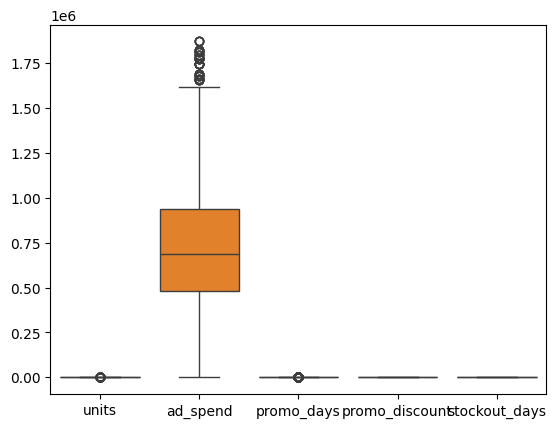

In [17]:
# df 전체 박스플랏

sns.boxplot(df)
plt.show()



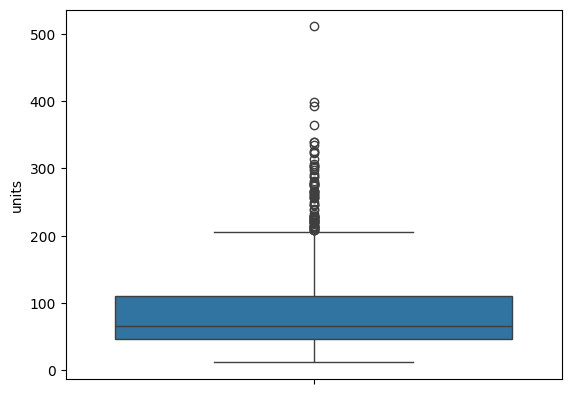



밸루카운트


units
52     35
40     27
50     27
47     27
43     25
       ..
214     1
205     1
264     1
364     1
12      1
Name: count, Length: 249, dtype: int64

In [18]:
# units 박스 플랏

sns.boxplot(df['units'])
plt.show()
print()
print()
print('밸루카운트')
df['units'].value_counts()

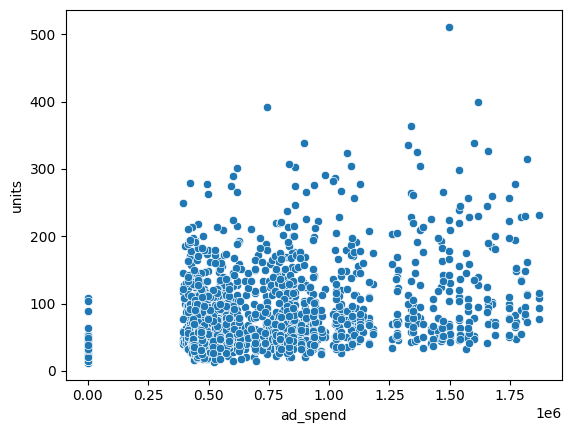


10분위수별 판매량 평균


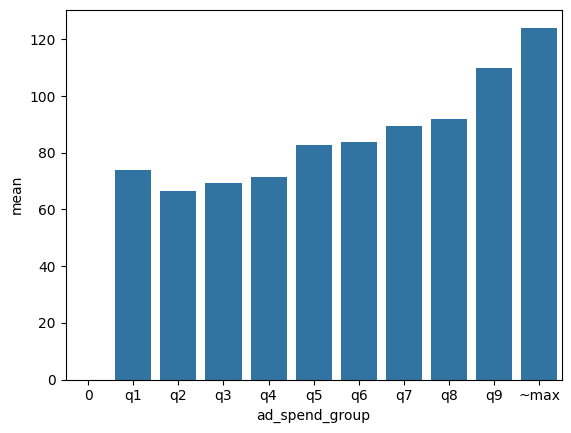

In [19]:
# units 과 ad_spend의 관계

sns.scatterplot(data=df, x='ad_spend', y='units')
plt.show()
print()
print('10분위수별 판매량 평균')
QuantilePlot(df, 'ad_spend', 'units','mean')
plt.show()

<Axes: >

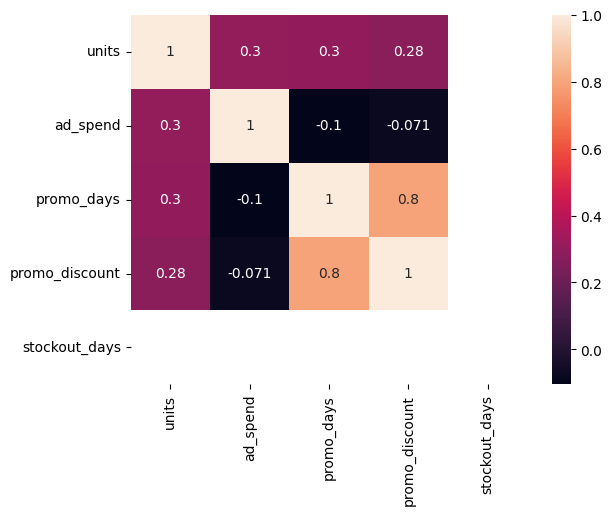

In [20]:
# 히트맵

sns.heatmap(df.corr(numeric_only=True), annot=True )




<Axes: xlabel='units', ylabel='Count'>

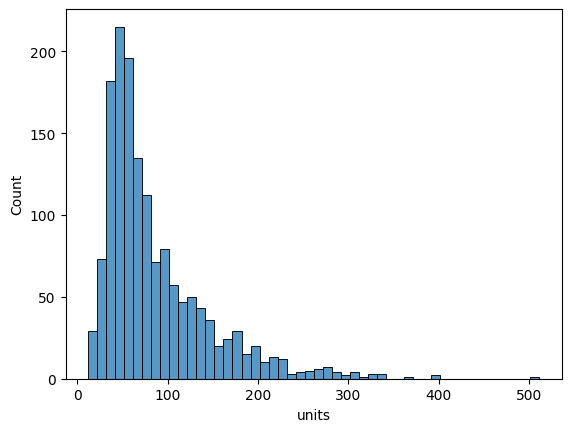

In [21]:
# 히스토 플랏 보기

sns.histplot(data=df, x='units', bins=50,stat='count' )

In [22]:
df_product

,sku,product_name,unit_cost_krw,list_price_krw,list_price_usd,lead_time_domestic_days,lead_time_fba_days,moq_units,fba_fee_usd,fba_storage_fee_usd_per_unit_month
0,A-SRM-100,발효 퍼스트 앰플 100ml,9500,38000,29.9,14,35,500,5.4,0.08
1,A-CRM-050,장벽 크림 50ml,10500,42000,39.9,14,35,500,4.9,0.05
2,A-CAP-HY,수분 캡슐 앰플 40caps,11250,45000,39.9,14,35,500,4.9,0.05
3,A-CAP-VC,광채 캡슐 앰플 40caps,11250,45000,39.9,14,35,500,4.9,0.05
4,A-CAP-PN,진정 캡슐 앰플 40caps,11250,45000,39.9,14,35,500,4.9,0.05


In [23]:
# 분기별 구분

# 날짜 데이터가 datetime 타입인지 확인
df['week_start'] = pd.to_datetime(df['week_start'])

# 분기 컬럼 추가
df['quarter'] = df['week_start'].dt.quarter

# 결과 확인
df[['week_start', 'quarter']].head()

df

,week_start,sku,product_name,channel,currency,units,ad_spend,promo_days,promo_discount,stockout_days,quarter
0,2024-08-26,A-SRM-100,발효 퍼스트 앰플 100ml,own_mall,KRW,132,892418.00,0,0.00,0,3
1,2024-08-26,A-CRM-050,장벽 크림 50ml,own_mall,KRW,55,892418.00,0,0.00,0,3
2,2024-08-26,A-CAP-HY,수분 캡슐 앰플 40caps,own_mall,KRW,32,892418.00,0,0.00,0,3
3,2024-08-26,A-CAP-VC,광채 캡슐 앰플 40caps,own_mall,KRW,65,892418.00,0,0.00,0,3
4,2024-08-26,A-CAP-PN,진정 캡슐 앰플 40caps,own_mall,KRW,37,892418.00,0,0.00,0,3
...,...,...,...,...,...,...,...,...,...,...,...
1524,2026-07-13,A-CAP-PN,진정 캡슐 앰플 40caps,amazon_us,USD,89,1629.65,4,0.25,0,3
1525,2026-07-20,A-SRM-100,발효 퍼스트 앰플 100ml,amazon_us,USD,104,1830.84,0,0.00,0,3
1526,2026-07-20,A-CRM-050,장벽 크림 50ml,amazon_us,USD,49,1830.84,0,0.00,0,3
1527,2026-07-20,A-CAP-HY,수분 캡슐 앰플 40caps,amazon_us,USD,32,1830.84,0,0.00,0,3


In [24]:
# 날짜 데이터 년 월 일 구분하여 인트 형식으로 컬럼 생성

df['year'] = df['week_start'].dt.year
df['month'] = df['week_start'].dt.month
df['day'] = df['week_start'].dt.day
#df['dayofweek'] = df['week_start'].dt.dayofweek

df.head()
#df.info()

,week_start,sku,product_name,channel,currency,units,ad_spend,promo_days,promo_discount,stockout_days,quarter,year,month,day
0,2024-08-26,A-SRM-100,발효 퍼스트 앰플 100ml,own_mall,KRW,132,892418.0,0,0.0,0,3,2024,8,26
1,2024-08-26,A-CRM-050,장벽 크림 50ml,own_mall,KRW,55,892418.0,0,0.0,0,3,2024,8,26
2,2024-08-26,A-CAP-HY,수분 캡슐 앰플 40caps,own_mall,KRW,32,892418.0,0,0.0,0,3,2024,8,26
3,2024-08-26,A-CAP-VC,광채 캡슐 앰플 40caps,own_mall,KRW,65,892418.0,0,0.0,0,3,2024,8,26
4,2024-08-26,A-CAP-PN,진정 캡슐 앰플 40caps,own_mall,KRW,37,892418.0,0,0.0,0,3,2024,8,26


In [25]:
# df_kr = df[df['currency']=='KRW']
# df_us = df[df['currency']=='USD']

# display(df_kr)
# print()
# print()
# display(df_us)

In [26]:
#df_kr.head(20)

In [27]:
#df_us

In [28]:
df['channel'].value_counts()

channel
own_mall     495
coupang      495
naver        495
amazon_us     29
Name: count, dtype: int64

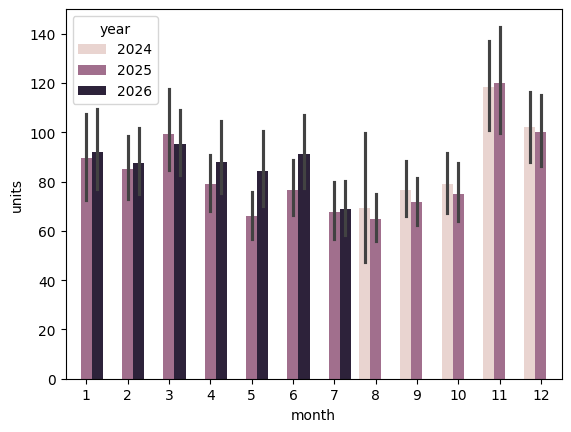

In [29]:
# 월별 판매량 체크
sns.barplot(data=df, x='month', y='units', hue='year')
plt.show()


In [30]:
#
display(df.groupby('year').mean(numeric_only=True))
display(df.groupby('month').mean(numeric_only=True))

,units,ad_spend,promo_days,promo_discount,stockout_days,quarter,month,day
year,,,,,,,,
2024,92.178947,989458.140351,1.073684,0.065614,0.0,3.684211,10.368421,16.526316
2025,83.408560,764769.712062,1.049287,0.061089,0.0,2.494163,6.571984,15.692607
2026,87.187773,660233.397838,1.159389,0.068013,0.0,1.716157,4.104803,15.113537


,units,ad_spend,promo_days,promo_discount,stockout_days,quarter,year,day
month,,,,,,,,
1,90.841667,797723.500000,0.566667,0.039583,0.0,1.0,2025.500000,16.000000
2,86.283333,800062.000000,0.733333,0.070417,0.0,1.0,2025.500000,13.000000
3,97.291667,833202.534722,1.736111,0.075694,0.0,1.0,2025.479167,16.958333
4,83.541667,762100.583333,0.650000,0.055417,0.0,2.0,2025.500000,17.000000
5,75.083333,688810.458333,0.566667,0.045000,0.0,2.0,2025.500000,15.000000
6,84.642424,663410.853939,2.187879,0.095152,0.0,2.0,2025.545455,16.090909
7,68.281818,579046.848273,0.727273,0.047727,0.0,3.0,2025.536364,15.309091
8,65.600000,734077.333333,0.506667,0.049333,0.0,3.0,2024.800000,16.800000
9,74.113333,834912.766667,0.440000,0.028333,0.0,3.0,2024.500000,15.500000


In [31]:
# 프로모션들어간 가격추가

# list_ = ['A-SRM-100', 'A-CRM-050', 'A-CAP-HY', 'A-CAP-VC', 'A-CAP-PN']



# for sku in list_:
#     sku_index_df = df_kr[df_kr['sku'] == sku].index
#     sku_index_pro = df_product[df_product['sku'] == sku].index


#     df_kr.loc[sku_index_df, 'promo_price'] = (
#         (1 - df_kr.loc[sku_index_df, 'promo_discount'])
#         * df_product.loc[sku_index_pro, 'list_price_krw'].iloc[0]
#     )

# for sku in list_:
#     sku_index_df = df_us[df_us['sku'] == sku].index
#     sku_index_pro = df_product[df_product['sku'] == sku].index


#     df_us.loc[sku_index_df, 'promo_price'] = (
#         (1 - df_us.loc[sku_index_df, 'promo_discount'])
#         * df_product.loc[sku_index_pro, 'list_price_usd'].iloc[0]
#     )

# for sku in list_:
#     sku_index_df = df[df['sku'] == sku].index
#     sku_index_pro = df_product[df_product['sku'] == sku].index


#     df.loc[sku_index_df, 'promo_price'] = (
#         (1 - df.loc[sku_index_df, 'promo_discount'])
#         * df_product.loc[sku_index_pro, 'list_price_usd'].iloc[0]
#     )

list_ = ['A-SRM-100', 'A-CRM-050', 'A-CAP-HY', 'A-CAP-VC', 'A-CAP-PN']

for sku in list_:

    sku_index_pro = df_product[df_product['sku'] == sku].index

    # KRW 데이터
    kr_index = df[
        (df['sku'] == sku) &
        (df['currency'] == 'KRW')
    ].index

    # USD 데이터
    us_index = df[
        (df['sku'] == sku) &
        (df['currency'] == 'USD')
    ].index

    # 원화 프로모션 가격
    df.loc[kr_index, 'promo_price'] = (
        (1 - df.loc[kr_index, 'promo_discount'])
        * df_product.loc[sku_index_pro, 'list_price_krw'].iloc[0]
    )

    # 달러 프로모션 가격
    df.loc[us_index, 'promo_price'] = (
        (1 - df.loc[us_index, 'promo_discount'])
        * df_product.loc[sku_index_pro, 'list_price_usd'].iloc[0]
    )


    

In [32]:
# 쓸모 없는 컬럼제거

df_del = df.copy()

df_del = df_del.drop(['week_start','product_name','stockout_days'], axis = 1)

df_del.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1514 entries, 0 to 1528
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sku             1514 non-null   object 
 1   channel         1514 non-null   object 
 2   currency        1514 non-null   object 
 3   units           1514 non-null   int64  
 4   ad_spend        1514 non-null   float64
 5   promo_days      1514 non-null   int64  
 6   promo_discount  1514 non-null   float64
 7   quarter         1514 non-null   int32  
 8   year            1514 non-null   int32  
 9   month           1514 non-null   int32  
 10  day             1514 non-null   int32  
 11  promo_price     1514 non-null   float64
dtypes: float64(3), int32(4), int64(2), object(3)
memory usage: 162.4+ KB


In [33]:
# sku << 리플레이스 인코딩, 통화 종류도 0,1 채널은 원핫인코딩

df_enc = df_del.copy()
df_enc['sku'] = df_enc['sku'].replace({'A-SRM-100':0, 'A-CRM-050':1, 'A-CAP-HY':2, 'A-CAP-VC':3, 'A-CAP-PN':4})
df_enc['currency'] = df_enc['currency'].replace({'KRW':0, 'USD':1})

df_enc_kr = df_enc[df_enc['currency']==0]
df_enc_us = df_enc[df_enc['currency']==1]


df_enc_kr = pd.get_dummies(df_enc_kr,columns=['channel'],dtype=int)
df_enc_us = pd.get_dummies(df_enc_us,columns=['channel'],dtype=int)
df_enc_us = df_enc_us.drop(['channel_amazon_us','currency'], axis = 1)
df_enc_kr = df_enc_kr.drop(['currency'], axis = 1)


#df_enc.head()
display(df_enc_kr)
print()
print()
display(df_enc_us)



/var/folders/rh/vtwd8cwd7cb4xgrq0w4vr5xm0000gn/T/ipykernel_78749/2518271435.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_enc['sku'] = df_enc['sku'].replace({'A-SRM-100':0, 'A-CRM-050':1, 'A-CAP-HY':2, 'A-CAP-VC':3, 'A-CAP-PN':4})
/var/folders/rh/vtwd8cwd7cb4xgrq0w4vr5xm0000gn/T/ipykernel_78749/2518271435.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_enc['currency'] = df_enc['currency'].replace({'KRW':0, 'USD':1})


,sku,units,ad_spend,promo_days,promo_discount,quarter,year,month,day,promo_price,channel_coupang,channel_naver,channel_own_mall
0,0,132,892418.0,0,0.0,3,2024,8,26,38000.0,0,0,1
1,1,55,892418.0,0,0.0,3,2024,8,26,42000.0,0,0,1
2,2,32,892418.0,0,0.0,3,2024,8,26,45000.0,0,0,1
3,3,65,892418.0,0,0.0,3,2024,8,26,45000.0,0,0,1
4,4,37,892418.0,0,0.0,3,2024,8,26,45000.0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1495,0,61,467027.0,0,0.0,3,2026,7,20,38000.0,0,1,0
1496,1,54,467027.0,0,0.0,3,2026,7,20,42000.0,0,1,0
1497,2,31,467027.0,0,0.0,3,2026,7,20,45000.0,0,1,0
1498,3,57,467027.0,0,0.0,3,2026,7,20,45000.0,0,1,0


,sku,units,ad_spend,promo_days,promo_discount,quarter,year,month,day,promo_price
1500,0,55,1153.37,7,0.20,2,2026,6,15,23.920
1501,1,14,1153.37,7,0.20,2,2026,6,15,31.920
1502,2,12,1153.37,7,0.20,2,2026,6,15,31.920
1503,3,20,1153.37,7,0.20,2,2026,6,15,31.920
1504,4,28,1153.37,7,0.20,2,2026,6,15,31.920
1505,0,54,1171.58,7,0.20,2,2026,6,22,23.920
1506,1,34,1171.58,7,0.20,2,2026,6,22,31.920
1507,2,23,1171.58,7,0.20,2,2026,6,22,31.920
1508,3,15,1171.58,7,0.20,2,2026,6,22,31.920
1509,4,47,1171.58,7,0.20,2,2026,6,22,31.920


In [34]:
# usd_index = df_enc[df_enc['currency']==1].index

# print(usd_index)
# print()
# df_enc.loc[usd_index]

In [35]:
# df_enc['dayofweek'].value_counts()

In [36]:
y_kr = df_enc_kr['units']
X_kr = df_enc_kr.drop('units',axis=1)

y_us = df_enc_us['units']
X_us = df_enc_us.drop('units',axis=1)

from sklearn.model_selection import train_test_split

X_train_k, X_test_k, y_train_k, y_test_k = train_test_split(X_kr, y_kr, test_size=0.2, random_state=100)
X_train_u, X_test_u, y_train_u, y_test_u = train_test_split(X_us, y_us, test_size=0.1, random_state=100)




In [37]:
X_kr.columns


Index(['sku', 'ad_spend', 'promo_days', 'promo_discount', 'quarter', 'year',
       'month', 'day', 'promo_price', 'channel_coupang', 'channel_naver',
       'channel_own_mall'],
      dtype='object')

In [38]:
# 스케일링

from sklearn.preprocessing import MinMaxScaler

mms_k = MinMaxScaler()
mms_u = MinMaxScaler()

x_train_k = mms_k.fit_transform(X_train_k)
x_test_k = mms_k.transform(X_test_k)
x_train_u = mms_u.fit_transform(X_train_u)
x_test_u = mms_u.transform(X_test_u)



In [39]:
# ML 학습

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from xgboost import XGBRegressor

lr_k = LinearRegression()
rfr_k = RandomForestRegressor()
abr_k = AdaBoostRegressor()
xgbr_k = XGBRegressor()
rg_k = Ridge()

lr_u = LinearRegression()
rfr_u = RandomForestRegressor()
abr_u = AdaBoostRegressor()
xgbr_u = XGBRegressor()


lr_k.fit(x_train_k, y_train_k)
rfr_k.fit(x_train_k, y_train_k)
abr_k.fit(x_train_k, y_train_k)
xgbr_k.fit(x_train_k, y_train_k)
rg_k.fit(x_train_k, y_train_k)

lr_u.fit(x_train_u, y_train_u)
rfr_u.fit(x_train_u, y_train_u)
abr_u.fit(x_train_u, y_train_u)
xgbr_u.fit(x_train_u, y_train_u)






[17:15:10] WARNING: src/objective/regression_obj.cu:152: reg:linear is now deprecated in favor of reg:squarederror.
[17:15:10] WARNING: src/objective/regression_obj.cu:152: reg:linear is now deprecated in favor of reg:squarederror.


XGBRegressor()

In [40]:
# 평가

y_pred_lr_k = lr_k.predict(x_test_k)
y_pred_rfr_k = rfr_k.predict(x_test_k)
y_pred_abr_k = abr_k.predict(x_test_k)
y_pred_xgbr_k = xgbr_k.predict(x_test_k)
y_pred_rg_k = rg_k.predict(x_test_k)

y_pred_lr_u = lr_u.predict(x_test_u)
y_pred_rfr_u = rfr_u.predict(x_test_u)
y_pred_abr_u = abr_u.predict(x_test_u)
y_pred_xgbr_u = xgbr_u.predict(x_test_u)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, classification_report
mae_lr_k = mean_absolute_error(y_test_k, y_pred_lr_k)
mae_rfr_k = mean_absolute_error(y_test_k, y_pred_rfr_k)
mae_abr_k = mean_absolute_error(y_test_k, y_pred_abr_k)
mae_xgbr_k = mean_absolute_error(y_test_k, y_pred_xgbr_k)
mae_rg_k = mean_absolute_error(y_test_k, y_pred_rg_k)
mse_lr_k = mean_squared_error(y_test_k, y_pred_lr_k)
mse_rfr_k = mean_squared_error(y_test_k, y_pred_rfr_k)
mse_abr_k = mean_squared_error(y_test_k, y_pred_abr_k)
mse_xgbr_k = mean_squared_error(y_test_k, y_pred_xgbr_k)
mse_rg_k = mean_squared_error(y_test_k, y_pred_rg_k)
r2_lr_k = r2_score(y_test_k, y_pred_lr_k)
r2_rfr_k = r2_score(y_test_k, y_pred_rfr_k)
r2_abr_k = r2_score(y_test_k, y_pred_abr_k)
r2_xgbr_k = r2_score(y_test_k, y_pred_xgbr_k)
r2_rg_k = r2_score(y_test_k, y_pred_rg_k)


mae_lr_u = mean_absolute_error(y_test_u, y_pred_lr_u)
mae_rfr_u = mean_absolute_error(y_test_u, y_pred_rfr_u)
mae_abr_u = mean_absolute_error(y_test_u, y_pred_abr_u)
mae_xgbr_u = mean_absolute_error(y_test_u, y_pred_xgbr_u)
mse_lr_u = mean_squared_error(y_test_u, y_pred_lr_u)
mse_rfr_u = mean_squared_error(y_test_u, y_pred_rfr_u)
mse_abr_u = mean_squared_error(y_test_u, y_pred_abr_u)
mse_xgbr_u = mean_squared_error(y_test_u, y_pred_xgbr_u)
r2_lr_u = r2_score(y_test_u, y_pred_lr_u)
r2_rfr_u = r2_score(y_test_u, y_pred_rfr_u)
r2_abr_u = r2_score(y_test_u, y_pred_abr_u)
r2_xgbr_u = r2_score(y_test_u, y_pred_xgbr_u)
#cr_lr = classification_report(y_test, y_pred_lr)
#cr_rfr = classification_report(y_test, y_pred_rfr)
#cr_abr = classification_report(y_test, y_pred_abr)
#cr_xgbr = classification_report(y_test, y_pred_xgbr)




In [41]:
print('KWR')
print('Linear')
print('MAE : ',mae_lr_k,' ','MSE : ',mse_lr_k,' ','R2 : ',r2_lr_k)
print()
print()
print('RandomForest')
print('MAE : ',mae_rfr_k,' ','MSE : ',mse_rfr_k,' ','R2 : ',r2_rfr_k)
print()
print()
print('AdaBoost')
print('MAE : ',mae_abr_k,' ','MSE : ',mse_abr_k,' ','R2 : ',r2_abr_k)
print()
print()
print('XGBR')
print('MAE : ',mae_xgbr_k,' ','MSE : ',mse_xgbr_k,' ','R2 : ',r2_xgbr_k)
print()
print()
print('Ridge')
print('MAE : ',mae_rg_k,' ','MSE : ',mse_rg_k,' ','R2 : ',r2_rg_k)
print()
print()


print('USD')
print('Linear')
print('MAE : ',mae_lr_u,' ','MSE : ',mse_lr_u,' ','R2 : ',r2_lr_u)
print()
print()
print('RandomForest')
print('MAE : ',mae_rfr_u,' ','MSE : ',mse_rfr_u,' ','R2 : ',r2_rfr_u)
print()
print()
print('AdaBoost')
print('MAE : ',mae_abr_u,' ','MSE : ',mse_abr_u,' ','R2 : ',r2_abr_u)
print()
print()
print('XGBR')
print('MAE : ',mae_xgbr_u,' ','MSE : ',mse_xgbr_u,' ','R2 : ',r2_xgbr_u)
print()
print()

KWR
Linear
MAE :  22.286195286195287   MSE :  989.025989057239   R2 :  0.7303505694185298


RandomForest
MAE :  16.654747474747477   MSE :  650.8312585858587   R2 :  0.8225564543055283


AdaBoost
MAE :  23.267367309117407   MSE :  895.5973118824893   R2 :  0.7558230947908567


XGBR
MAE :  16.175881042223587   MSE :  545.2033585791336   R2 :  0.8513549928732356


Ridge
MAE :  22.84664967940782   MSE :  1023.1535400520555   R2 :  0.721045986126776


USD
Linear
MAE :  22.30897284587739   MSE :  535.4809881222716   R2 :  0.454456770081453


RandomForest
MAE :  28.893333333333334   MSE :  1033.9063333333334   R2 :  -0.05333450305637322


AdaBoost
MAE :  27.833333333333332   MSE :  1027.7083333333333   R2 :  -0.04702003622368123


XGBR
MAE :  21.909666697184246   MSE :  543.096912881927   R2 :  0.4466977342158317




In [42]:
X_kr.columns

x_temp = mms_k.transform(X_kr.iloc[[335]])

y_pred_temp = xgbr_k.predict(x_temp)

y_pred_temp, df_enc_kr.loc[335,'units']

(array([97.83777], dtype=float32), 307)

In [43]:
df_enc_kr.loc[335]

sku                      0.00
units                  307.00
ad_spend            832200.00
promo_days               5.00
promo_discount           0.25
quarter                  4.00
year                  2025.00
month                   12.00
day                      8.00
promo_price          28500.00
channel_coupang          0.00
channel_naver            0.00
channel_own_mall         1.00
Name: 335, dtype: float64

In [44]:
X_kr.loc[335]

sku                      0.00
ad_spend            832200.00
promo_days               5.00
promo_discount           0.25
quarter                  4.00
year                  2025.00
month                   12.00
day                      8.00
promo_price          28500.00
channel_coupang          0.00
channel_naver            0.00
channel_own_mall         1.00
Name: 335, dtype: float64

In [45]:
import random
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import to_categorical

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)
tf.keras.utils.set_random_seed(42)


In [46]:

dl_k = Sequential([
    Dense(64, 'selu'),
    Dense(128, 'selu'),
    BatchNormalization(),
    Dense(256, 'selu'),
    Dense(1,'linear')
    
])

dl_k.compile(loss='mse', optimizer='adam', metrics=['mae'])

estop = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
mcheck = ModelCheckpoint('best_dl_model.h5', save_best_only=True)

history_k = dl_k.fit(x_train_k, y_train_k, epochs=100, batch_size=10,validation_data=(x_test_k, y_test_k) ,callbacks=[estop, mcheck]) ## validation_data 꼭!!! 넣기@@@


Epoch 1/100
119/119 [==============================] - 0s 1ms/step - loss: 6115.1069 - mae: 66.6428 - val_loss: 6144.7075 - val_mae: 65.2247
Epoch 2/100
119/119 [==============================] - 0s 996us/step - loss: 2188.4160 - mae: 36.5478 - val_loss: 1902.2662 - val_mae: 30.8255
Epoch 3/100
 84/119 [====================>.........] - ETA: 0s - loss: 1655.3232 - mae: 30.1783

/Users/jeongheehoon/anaconda3/envs/aice/lib/python3.10/site-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


119/119 [==============================] - 0s 816us/step - loss: 1640.8574 - mae: 29.8800 - val_loss: 1044.1229 - val_mae: 24.1049
Epoch 4/100
119/119 [==============================] - 0s 811us/step - loss: 1427.3716 - mae: 27.4387 - val_loss: 1008.2256 - val_mae: 22.8998
Epoch 5/100
119/119 [==============================] - 0s 828us/step - loss: 1418.5518 - mae: 27.0938 - val_loss: 988.7783 - val_mae: 23.1139
Epoch 6/100
119/119 [==============================] - 0s 745us/step - loss: 1244.2158 - mae: 24.6322 - val_loss: 1016.1019 - val_mae: 22.5755
Epoch 7/100
119/119 [==============================] - 0s 716us/step - loss: 1227.6323 - mae: 24.7549 - val_loss: 1316.0846 - val_mae: 22.9281
Epoch 8/100
119/119 [==============================] - 0s 740us/step - loss: 1246.5334 - mae: 24.4972 - val_loss: 870.6729 - val_mae: 20.7197
Epoch 9/100
119/119 [==============================] - 0s 705us/step - loss: 1165.1467 - mae: 23.8493 - val_loss: 899.4487 - val_mae: 22.4626
Epoch 10/100
1

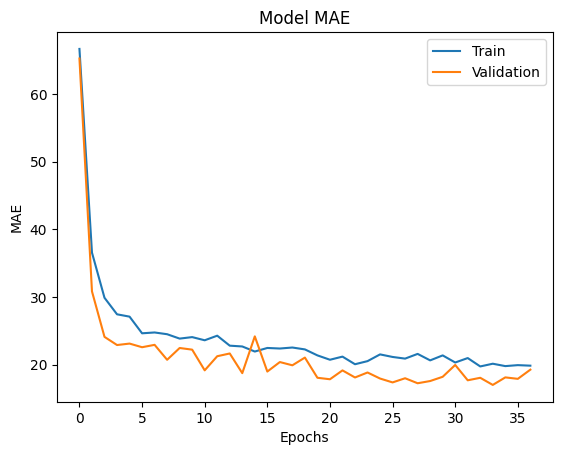

In [47]:
plt.figure()
plt.plot(history_k.history['mae'], label = 'Train')
plt.plot(history_k.history['val_mae'], label = 'Validation')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.title('Model MAE')
plt.legend()

In [48]:

# 학습 완료된 모델 저장
xgbr_k.save_model("sales_model.json")

import joblib

# 학습된 XGBoost 모델 저장
joblib.dump(xgbr_k, 'xgbr_model_k.joblib')

# 학습된 MinMaxScaler 저장
joblib.dump(mms_k, 'minmax_scaler_k.joblib')

# 학습된 XGBoost 모델 저장
joblib.dump(xgbr_u, 'xgbr_model_u.joblib')

# 학습된 MinMaxScaler 저장
joblib.dump(mms_u, 'minmax_scaler_u.joblib')


import pickle

# 모델 패키지 생성
model_package = {
    'model': xgbr_k,
    'scaler': mms_k,
    'feature_columns': list(mms_k.feature_names_in_)
}

# PKL 파일 저장
with open('sales_prediction.pkl', 'wb') as f:
    pickle.dump(model_package, f)


X_kr.columns

Index(['sku', 'ad_spend', 'promo_days', 'promo_discount', 'quarter', 'year',
       'month', 'day', 'promo_price', 'channel_coupang', 'channel_naver',
       'channel_own_mall'],
      dtype='object')

In [49]:
X_us.columns

Index(['sku', 'ad_spend', 'promo_days', 'promo_discount', 'quarter', 'year',
       'month', 'day', 'promo_price'],
      dtype='object')

In [50]:
# futureplan을 받아서 예측 model 수행후 서브미션 파일 만드는 함수

# def fut_to_sub(future, submission, trained_model, scaler):
#     future_ = pd.read_csv(future)
#     submission = pd.read_csv(submission)
    

In [51]:
# futureplan 을 예측하기!

df_future = pd.read_csv('future_plan_4w.csv')
df_future.rename(columns={'planned_ad_spend': 'ad_spend'}, inplace=True)

# 날짜 데이터가 datetime 타입인지 확인
df_future['week_start'] = pd.to_datetime(df_future['week_start'])

# 분기 컬럼 추가
df_future['quarter'] = df_future['week_start'].dt.quarter

# 결과 확인
#df_future[['week_start', 'quarter']].head()


# 날짜 데이터 년 월 일 구분하여 인트 형식으로 컬럼 생성

df_future['year'] = df_future['week_start'].dt.year
df_future['month'] = df_future['week_start'].dt.month
df_future['day'] = df_future['week_start'].dt.day


# 프로모션들어간 가격추가

list_ = ['A-SRM-100', 'A-CRM-050', 'A-CAP-HY', 'A-CAP-VC', 'A-CAP-PN']

for sku in list_:

    sku_index_pro = df_product[df_product['sku'] == sku].index

    # KRW 데이터
    kr_index = df_future[
        (df_future['sku'] == sku) &
        (df_future['currency'] == 'KRW')
    ].index

    # USD 데이터
    us_index = df_future[
        (df_future['sku'] == sku) &
        (df_future['currency'] == 'USD')
    ].index

    # 원화 프로모션 가격
    df_future.loc[kr_index, 'promo_price'] = (
        (1 - df_future.loc[kr_index, 'promo_discount'])
        * df_product.loc[sku_index_pro, 'list_price_krw'].iloc[0]
    )

    # 달러 프로모션 가격
    df_future.loc[us_index, 'promo_price'] = (
        (1 - df_future.loc[us_index, 'promo_discount'])
        * df_product.loc[sku_index_pro, 'list_price_usd'].iloc[0]
    )




df_del_ft = df_future.copy()

df_del_ft = df_del_ft.drop(['week_start','product_name'], axis = 1)


# sku << 리플레이스 인코딩, 통화 종류도 0,1 채널은 원핫인코딩

df_enc_ft = df_del_ft.copy()
df_enc_ft['sku'] = df_enc_ft['sku'].replace({'A-SRM-100':0, 'A-CRM-050':1, 'A-CAP-HY':2, 'A-CAP-VC':3, 'A-CAP-PN':4})
df_enc_ft['currency'] = df_enc_ft['currency'].replace({'KRW':0, 'USD':1})
df_enc_ft_kr = df_enc_ft[df_enc_ft['currency']==0]
df_enc_ft_us = df_enc_ft[df_enc_ft['currency']==1]


df_enc_ft_kr = pd.get_dummies(df_enc_ft_kr,columns=['channel'],dtype=int)
df_enc_ft_us = pd.get_dummies(df_enc_ft_us,columns=['channel'],dtype=int)
df_enc_ft_us = df_enc_ft_us.drop(['channel_amazon_us','currency'], axis = 1)
df_enc_ft_kr = df_enc_ft_kr.drop(['currency'], axis = 1)


# 데이터 스케일링
x_test_ft_kr = mms_k.transform(df_enc_ft_kr)
x_test_ft_us = mms_u.transform(df_enc_ft_us)


y_pred_xgbr_f_k = xgbr_k.predict(x_test_ft_kr)
y_pred_xgbr_f_u = xgbr_u.predict(x_test_ft_us)



# 제출 양식 불러오기
df_submit = pd.read_csv('submission_template.csv')

# 머신러닝 모델 예측 결과


# 예측 결과 입력
kr_index_ = df_future[
     (df_future['currency'] == 'KRW')
  ].index
us_index_ = df_future[
     (df_future['currency'] == 'USD')
  ].index

df_submit.loc[kr_index_, 'pred_units'] = (
    np.maximum(y_pred_xgbr_f_k, 0)
    .round()
    .astype(int)
)

df_submit.loc[us_index_, 'pred_units'] = (
    np.maximum(y_pred_xgbr_f_u, 0)
    .round()
    .astype(int)
)

df_submit.to_csv(
    'submission_final.csv',
    index=False,
    encoding='utf-8-sig'
)


/var/folders/rh/vtwd8cwd7cb4xgrq0w4vr5xm0000gn/T/ipykernel_78749/4121547652.py:66: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_enc_ft['sku'] = df_enc_ft['sku'].replace({'A-SRM-100':0, 'A-CRM-050':1, 'A-CAP-HY':2, 'A-CAP-VC':3, 'A-CAP-PN':4})
/var/folders/rh/vtwd8cwd7cb4xgrq0w4vr5xm0000gn/T/ipykernel_78749/4121547652.py:67: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_enc_ft['currency'] = df_enc_ft['currency'].replace({'KRW':0, 'USD':1})


In [52]:
#y_pred_xgbr

In [53]:
# # 스케일러 학습에 사용된 컬럼
# print("학습 Feature:")
# print(mms.feature_names_in_)

# # 현재 예측 데이터 컬럼
# print("\n예측 Feature:")
# print(df_enc_ft.columns)

# # 예측 데이터에만 있는 컬럼
# print("\n추가된 컬럼:")
# print(
#     set(df_enc_ft.columns)
#     - set(mms.feature_names_in_)
# )

# # 학습 데이터에만 있는 컬럼
# print("\n누락된 컬럼:")
# print(
#     set(mms.feature_names_in_)
#     - set(df_enc_ft.columns)
# )

In [54]:
a = xgbr_k.feature_importances_

b = X_kr.columns

c = pd.DataFrame({'feature':b, 'importance' : a}).sort_values('importance', ascending=False)
display(c)

,feature,importance
0,sku,0.275502
9,channel_coupang,0.219327
8,promo_price,0.116186
3,promo_discount,0.101564
10,channel_naver,0.098383
2,promo_days,0.089656
1,ad_spend,0.034829
6,month,0.028590
4,quarter,0.018142
5,year,0.010235
